Leakage checks: anything written or edited after a serial takes off would let the model see the future. Sources: `modeling/03_compare.py`, `embedding/11_watermark_check.py`, `cover/01_cover_pipeline.ipynb`, `embedding/04_tags_trend.ipynb`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load = lambda rel: json.loads((ROOT / rel).read_text())
show = lambda rel, width=720: display(Image(filename=str(ROOT / rel), width=width))
pd.set_option("display.precision", 3)

Blurbs and watermarks, 2023 test year. Blurbs are the 2025 version (authors of hits add "Book 2", Kindle, Patreon or Audible links later); watermarks are anti-piracy sentences inserted into chapter text.

In [2]:
lc = load("modeling/out/results.json")["leak_checks"]
pd.DataFrame({"blurb mentions Kindle / Patreon / Book 2": lc["blurb_marker"], "chapter text has a watermark": lc["watermark"]}).T[
    ["share_of_test", "top10_rate_if_flagged", "auc_of_flag_alone"]].rename(columns={
    "share_of_test": "share of test serials", "top10_rate_if_flagged": "hit rate if flagged", "auc_of_flag_alone": "AUC of the flag alone"})

,share of test serials,hit rate if flagged,AUC of the flag alone
blurb mentions Kindle / Patreon / Book 2,0.078,0.455,0.652
chapter text has a watermark,0.097,0.111,0.506


In [3]:
print("Main model AUC without watermarked serials:", lc["watermark"]["without_flagged_books"]["lr_SAT"]["auc"], "(all serials: 0.887)")
print("Blurb-only model AUC without flagged blurbs:", lc["blurb_marker"]["without_flagged_books"]["lr_D"]["auc"], "(all serials: 0.873)")

Main model AUC without watermarked serials: 0.889 (all serials: 0.887)
Blurb-only model AUC without flagged blurbs: 0.837 (all serials: 0.873)


Covers: the cover URL stores the upload time of the current cover. Covers that appeared or changed after chapter 3 come with far more hits.

In [4]:
st = pd.read_csv(ROOT / "cover/out/status/status_by_year.csv")
pooled = st[st.year == "2017-2022"].set_index("status")[["n", "share_of_year", "top10_rate"]]
pooled.columns = ["serials (2017–2022)", "share", "hit rate"]
pooled.sort_values("hit rate", ascending=False)

,serials (2017–2022),share,hit rate
status,,,
after_ch3,4559,2.000e-01,0.212
no_timestamp,6323,2.773e-01,0.116
image_changed,14,6.140e-04,0.071
valid,7163,3.142e-01,0.070
no_custom_cover,4741,2.079e-01,0.019


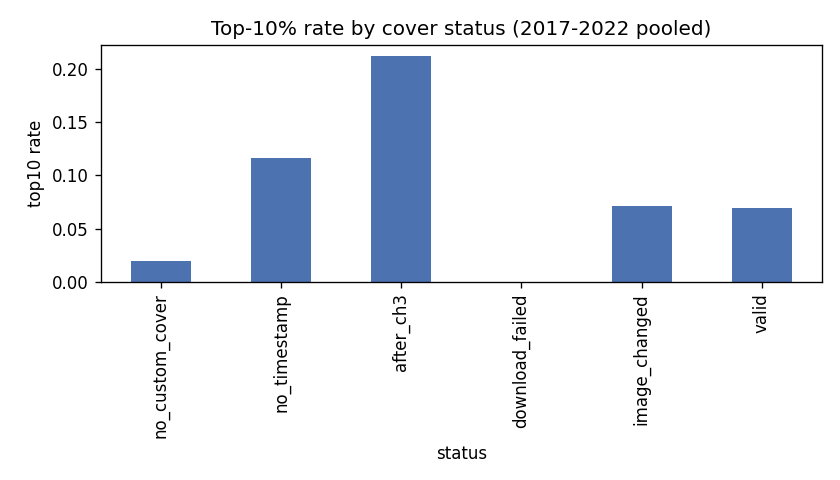

In [5]:
show("cover/out/status/top10_by_status.png", 600)

Tags are a 2025 snapshot too. Progression became common only around 2020; among 2016–2017 serials, the few that carry it today are hits several times as often as average, because authors of serials that kept going added it later.

In [6]:
tr = load("embedding/out/tags_summary.json")["trajectories"]["Progression"]
pd.DataFrame({"share of serials with the tag (%)": tr["supply"], "lift (hit share / overall share)": tr["lift"]}, index=range(2016, 2025)).T

,2016,2017,2018,2019,2020,2021,2022,2023,2024
share of serials with the tag (%),0.270,0.280,0.970,1.540,7.630,33.540,34.21,36.360,34.830
lift (hit share / overall share),4.966,2.838,3.897,3.977,2.718,1.782,1.94,1.869,1.977


Watermarks fake a 2016 → 2017 jump in the embedding space:

In [7]:
w = load("embedding/out/watermark_check.json")
pd.DataFrame({"all serials": {"watermark share in 2016": w["share_books_with_watermark_by_year"]["2016"],
                              "supply shift 2016 → 2017": w["all_books"]["supply_from_2016"]["2017"],
                              "preference similarity 8 years apart": w["all_books"]["dir_by_gap_disatt"]["8"]},
              "watermarked serials removed": {"watermark share in 2016": 0,
                              "supply shift 2016 → 2017": w["no_watermark"]["supply_from_2016"]["2017"],
                              "preference similarity 8 years apart": w["no_watermark"]["dir_by_gap_disatt"]["8"]}})

,all serials,watermarked serials removed
watermark share in 2016,0.753,0.000
supply shift 2016 → 2017,0.017,0.001
preference similarity 8 years apart,0.851,0.935


Takeaways: blurbs (+5.8 points) and earlier books' success (+3.3) help but are edited or inflated after success, so they are excluded and kept only as an upper bound. Only covers uploaded before chapter 3 and never changed can be used; covers added later come with three times the hit rate. Watermarks do not affect the model (AUC 0.889 vs 0.887) but fake a 2016 jump in trend analyses, so trend numbers use the watermark-free version. Not fixable here: tags, text and followers are one 2025 snapshot, so results may be somewhat optimistic.